# 04 · CNN (Convolutional Neural Network) Model

**Goal:** build a model designed for images and compare it with the ANN from notebook 03.


## 1 Convolution Layers

In [1]:
import tensorflow as tf 
from tensorflow.keras  import layers , models 
import matplotlib.pyplot as plt  

In [2]:
from pathlib import Path

PROJECT_DIR = Path("..")
TRAIN_DIR = PROJECT_DIR / "dataset" / "Training"
IMG_SIZE = (224, 224)

sample_path = next((TRAIN_DIR / "glioma").glob("*.jpg"))

sample_img = tf.keras.utils.load_img(sample_path,target_size=IMG_SIZE,color_mode="grayscale")
sample_array = tf.keras.utils.img_to_array(sample_img)
sample_array = sample_array / 255.0
sample_batch = tf.expand_dims(sample_array, axis=0)

print("Image shape:", sample_array.shape)
print("Batch shape:", sample_batch.shape)

Image shape: (224, 224, 1)
Batch shape: (1, 224, 224, 1)


In [3]:
conv_layer = layers.Conv2D(filters=32,kernel_size=(3,3),activation='relu',padding='same')
feature_maps = conv_layer(sample_batch) 
 
print("Original shape:", sample_batch.shape) 
print("Feature map shape:", feature_maps.shape) 

Original shape: (1, 224, 224, 1)
Feature map shape: (1, 224, 224, 32)


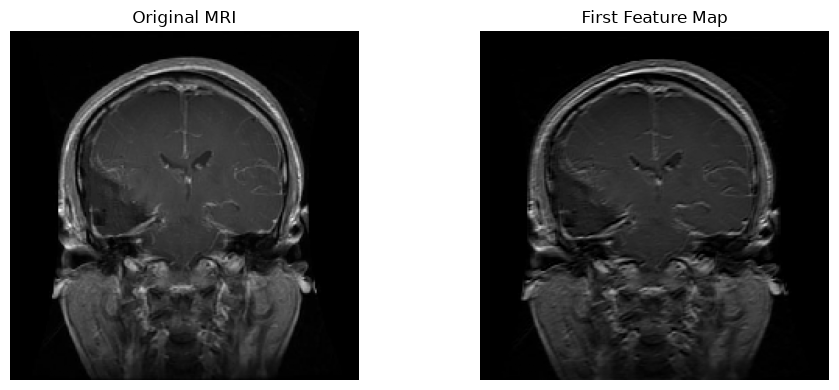

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_array.squeeze(), cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(feature_maps[0, :, :, 0].numpy(), cmap="gray")
plt.title("First Feature Map")
plt.axis("off")

plt.tight_layout()
plt.show()

## 2  Filters and Feature Maps

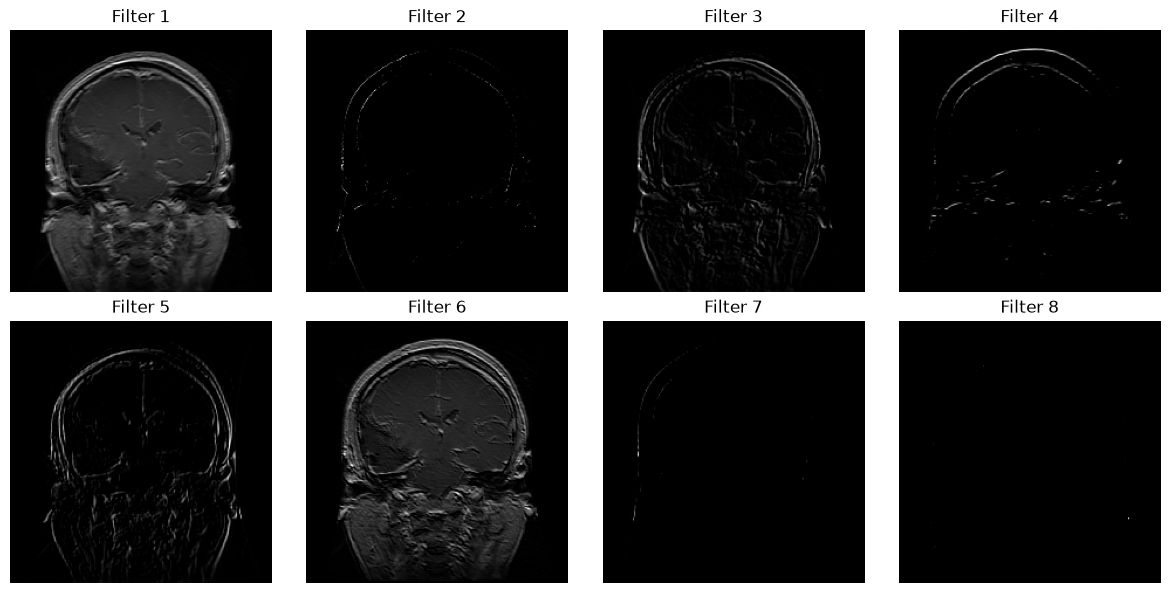

In [5]:
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1) 
    plt.imshow(feature_maps[0, :, :, i].numpy(),cmap="gray")
    plt.title(f"Filter {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
weights, biases = conv_layer.get_weights()

print("Filter weights shape:", weights.shape)
print("Bias shape:", biases.shape)
print("Feature maps shape:", feature_maps.shape)

Filter weights shape: (3, 3, 1, 32)
Bias shape: (32,)
Feature maps shape: (1, 224, 224, 32)


## 3 Pooling Layers

In [7]:
pool_layer = layers.MaxPooling2D(pool_size=(2, 2),strides=2)
pooled_maps = pool_layer(feature_maps)

print("Before pooling:", feature_maps.shape)
print("After pooling:", pooled_maps.shape)

Before pooling: (1, 224, 224, 32)
After pooling: (1, 112, 112, 32)


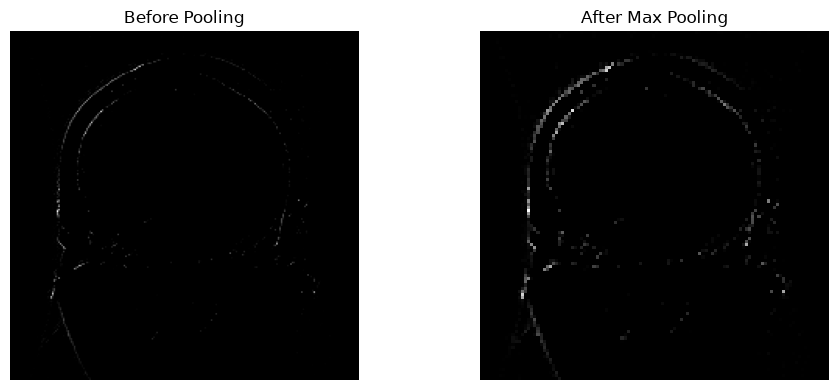

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(feature_maps[0, :, :, 1].numpy(), cmap="gray")
plt.title("Before Pooling")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pooled_maps[0, :, :, 1].numpy(), cmap="gray")
plt.title("After Max Pooling")
plt.axis("off")

plt.tight_layout()
plt.show()

## 4 Flatten and Dense Layers

In [9]:
flatten_layer = layers.Flatten()
flattened_output = flatten_layer(pooled_maps)

dense_layer = layers.Dense(128, activation="relu")
dense_output = dense_layer(flattened_output)

output_layer = layers.Dense(4, activation="softmax")
predictions = output_layer(dense_output)

print("Pooled shape:", pooled_maps.shape)
print("Flattened shape:", flattened_output.shape)
print("Dense output shape:", dense_output.shape)
print("Prediction shape:", predictions.shape)

Pooled shape: (1, 112, 112, 32)
Flattened shape: (1, 401408)
Dense output shape: (1, 128)
Prediction shape: (1, 4)


## 5  CNN Training

In [10]:
cnn_model = models.Sequential([layers.Input(shape=(224, 224, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(4, activation="softmax")])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,572 (98.07 MB)

 Trainable params: 25,709,572 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn_model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [12]:
def preprocess_cnn_image(image_path, label):
    image = tf.io.read_file(image_path) 
    image = tf.io.decode_image(image,channels=1,expand_animations=False)
    image.set_shape([None, None, 1]) 
    image = tf.image.resize(image, IMG_SIZE) 
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.ensure_shape(image, [224, 224, 1])
    return image, label

In [13]:

import numpy as np
from sklearn.model_selection import train_test_split

TRAIN_DIR = PROJECT_DIR / "dataset" / "Training"

class_names = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
class_to_label = {name: i for i, name in enumerate(class_names)}

paths, labels = [], [] 
for class_name in class_names: 
    for path in (TRAIN_DIR / class_name).rglob("*"):
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            paths.append(str(path))
            labels.append(class_to_label[class_name])

X_train, X_val, y_train, y_val = train_test_split(np.array(paths),np.array(labels),test_size=0.20,random_state=42,stratify=labels)

print("Training:", len(X_train)) 
print("Validation:", len(X_val))

Training: 4480
Validation: 1120


In [14]:
BATCH_SIZE = 16

def create_cnn_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_cnn_image,num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        dataset = dataset.shuffle(buffer_size=len(paths),seed=42)

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


cnn_train_dataset = create_cnn_dataset(X_train, y_train, training=True)
cnn_val_dataset = create_cnn_dataset(X_val, y_val)


In [15]:
for images, labels in cnn_train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", tf.reduce_min(images).numpy(),
          "to", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 1)
Label batch shape: (16,)
Pixel range: 0.0 to 1.0


In [16]:
history_cnn = cnn_model.fit(cnn_train_dataset,validation_data=cnn_val_dataset,epochs=10)

Epoch 1/10


d:\MRI-Brain-Tumor-Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


280/280 ━━━━━━━━━━━━━━━━━━━━ 125s 432ms/step - accuracy: 0.7739 - loss: 0.6427 - val_accuracy: 0.8491 - val_loss: 0.3953
Epoch 2/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 3577s 13s/step - accuracy: 0.9163 - loss: 0.2221 - val_accuracy: 0.8839 - val_loss: 0.3343
Epoch 3/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 136s 474ms/step - accuracy: 0.9663 - loss: 0.1023 - val_accuracy: 0.9054 - val_loss: 0.3037
Epoch 4/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 122s 425ms/step - accuracy: 0.9855 - loss: 0.0453 - val_accuracy: 0.9161 - val_loss: 0.3069
Epoch 5/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 135s 475ms/step - accuracy: 0.9893 - loss: 0.0294 - val_accuracy: 0.9080 - val_loss: 0.3144
Epoch 6/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 132s 468ms/step - accuracy: 0.9810 - loss: 0.0501 - val_accuracy: 0.9187 - val_loss: 0.4092
Epoch 7/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 137s 480ms/step - accuracy: 0.9922 - loss: 0.0230 - val_accuracy: 0.9277 - val_loss: 0.3171
Epoch 8/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 138s 485ms/step - accuracy: 0.9982 - loss: 0.007

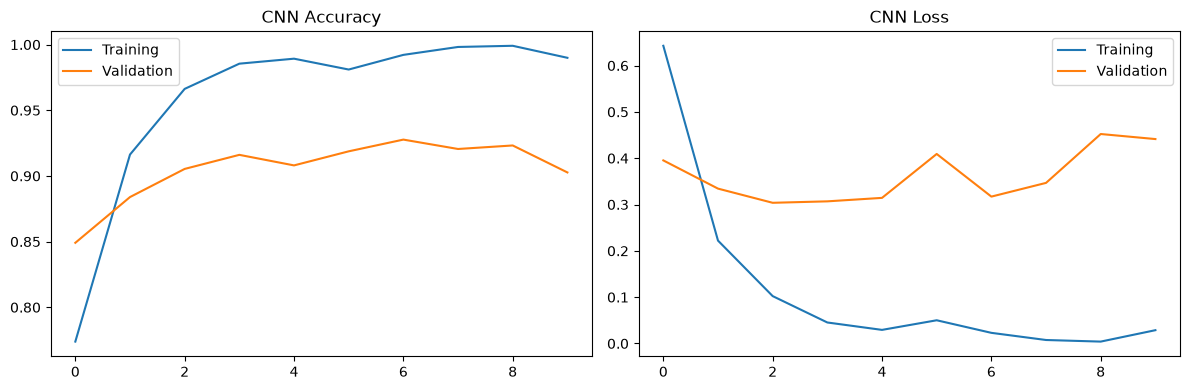

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.savefig(PROJECT_DIR / "images" / "cnn_training_results.png",dpi=300,bbox_inches="tight") 
plt.show()

In [ ]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
cnn_model.save(MODEL_DIR / "cnn_brain_tumor.keras")


In [19]:
import json
with open(MODEL_DIR / "cnn_training_history.json", "w") as f:
    json.dump(history_cnn.history, f)

## Summary

| Item | Value |
|---|---|
| Input | 224 x 224 grayscale image, kept 2D (224, 224, 1) |
| Architecture | Conv(32) → MaxPool → Conv(64) → MaxPool → Flatten → Dense(128) → Dense(4, softmax) |
| Parameters | about 25.7 million (almost all in the Dense layer after Flatten) |
| Training | Adam, sparse categorical crossentropy, batch size 16, 10 epochs |
| Saved files | `models/cnn_brain_tumor.keras`, `models/cnn_training_history.json` |

**Figure saved for the README:** `cnn_training_results.png`

**Next:** `05_model_evaluation.ipynb`